## Data Preprocessing

In this document, I will be looking into data preprocessing steps. In the EDA, I looked into identifying and understanding the data and its imbalances. Based on this, now I am mainly looking into:

- How can I transform my data into correct inputs for the model?

## Importing Libraries and Loading Data

In [1]:
import pandas as pd
import torch
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

data_path = Path("../data/OpenEarthMap_wo_xBD")
assert data_path.is_dir(), "Dataset folder not found."
print("Data path:", data_path)
print("PyTorch version:", torch.__version__)

Data path: ..\data\OpenEarthMap_wo_xBD
PyTorch version: 2.15.0+cpu


## Avaliable Image-Mask Pairs   

I will be creating a table containing the paths and region of each pair.

In [2]:
pairs=[]

for image in sorted(data_path.glob("*/images/*tif")):
    region = image.parent.parent.name
    mask=data_path / region / "labels" / image.name

    if mask.is_file():
        pairs.append([region, image, mask])

pairs_df=pd.DataFrame(pairs, columns=["region", "image", "mask"])

print("Pairs: ", len(pairs_df))
print("Regions: ", pairs_df["region"].nunique())

preview = pairs_df.head().copy()
preview["image"] = preview["image"].map(lambda path: path.name)
preview["mask"] = preview["mask"].map(lambda path: path.name)

display(preview)

Pairs:  2687
Regions:  75


,region,image,mask
0,aachen,aachen_1.tif,aachen_1.tif
1,aachen,aachen_10.tif,aachen_10.tif
2,aachen,aachen_11.tif,aachen_11.tif
3,aachen,aachen_12.tif,aachen_12.tif
4,aachen,aachen_13.tif,aachen_13.tif


## Validating Image-Mask Pairs
Checking if all paired files can be read, there are only three RGB channels and dimensions are equal in the pairs.

In [3]:
for region, image_path, mask_path in pairs:
    with Image.open(image_path) as source:
        image = np.array(source)

    with Image.open(mask_path) as source:
        mask = np.array(source)

    assert image.ndim == 3 and image.shape[2] == 3, image_path.name
    assert image.dtype==np.uint8, image_path.name

    assert mask.ndim == 2, mask_path.name
    assert np.issubdtype(mask.dtype, np.integer), mask_path.name
    assert np.isin(mask, range(9)).all(), mask_path.name

    assert image.shape[:2] == mask.shape,image_path.name

print("Pairs verified successfully: ", len(pairs))

Pairs verified successfully:  2687


All pairs checked above are validated and are complete to contiinue the steps of this process. Now I will check if there are duplicate images, to check for possible data leakage in the future.

## Checking duplicate Images/Masks

In [4]:
checks = []

for region, image_path, mask_path in pairs:
    with Image.open(image_path) as source:
        image = np.array(source)

    with Image.open(mask_path) as source:
        mask = np.array(source)

    image_hash = hashlib.md5(image.tobytes()).hexdigest()
    mask_hash = hashlib.md5(mask.tobytes()).hexdigest()

    checks.append([image.shape, image_hash, mask_hash])

checks_df = pd.DataFrame(
    checks, columns=["shape", "image_hash", "mask_hash"]
)

print("Repeated images:",
      checks_df.duplicated(["shape", "image_hash"]).sum())

print("Repeated pairs:",
      checks_df.duplicated(["shape", "image_hash", "mask_hash"]).sum())

Repeated images: 0
Repeated pairs: 0


There are no repeated images/masks. We can proceed to splitting our data.

## Geographical Data Splits
As seen in **01_EDA_loading.ipynb** our data is unbalanced between geographical locations, so for splitting, we will need to do a geographical split by region. With this, I hope to reach better generalization of the model into unseen regions.

In [5]:
regions=sorted(pairs_df["region"].unique())

rng = np.random.default_rng(seed=42)
regions=rng.permutation(regions)

n_train = int(len(regions)*0.7)
n_val = int(len(regions)*0.15)

train_regions = regions[:n_train]
validation_regions = regions[n_train:n_train+n_val]     #slicing   
test_regions = regions[n_train+n_val:]

pairs_df["split"] = "train"

pairs_df.loc[pairs_df["region"].isin(validation_regions), "split"] = "validation"
pairs_df.loc[pairs_df["region"].isin(test_regions), "split"] = "test"

split_summary = pairs_df.groupby("split").agg(
    Images=("image", "count"),
    Regions=("region", "nunique")
)

display(split_summary)

,Images,Regions
split,,
test,470,12
train,1942,52
validation,275,11


Based on this split, now I will look into the coverage of this split, to check if all classes are represented in these splits, otherwise it will be a problem for the future, if all of them are not represented, since the model will be biased.

## Class Coverage by Split

In [6]:
counts = {
    "train": [0] * 8,
    "validation": [0] * 8,
    "test": [0] * 8
}

for row in pairs_df.itertuples():
    with Image.open(row.mask) as source:
        mask = np.array(source)

    for label in range(1, 9):
        if (mask == label).any():
            counts[row.split][label - 1] += 1

coverage = pd.DataFrame(
    counts,
    index=[
        "Bareland", "Rangeland", "Developed Space", "Road",
        "Tree", "Water", "Agriculture Land", "Building"
    ]
)

display(coverage)

,train,validation,test
Bareland,263,71,77
Rangeland,1887,271,468
Developed Space,1888,261,457
Road,1818,254,458
Tree,1920,273,462
Water,969,178,294
Agriculture Land,883,134,149
Building,1892,255,456


The split above represents all classes in all splits, but bareland is still less represented than other classes. I won't re-do the split, however in the future, depending on model results, I may change or check better this decisions in the split.

## Pixel Distribution

In [7]:
pixel_counts = {
    "train": [0] * 8,
    "validation": [0] * 8,
    "test": [0] * 8
}

for row in pairs_df.itertuples():
    with Image.open(row.mask) as source:
        mask = np.array(source)

    for label in range(1, 9):
        pixel_counts[row.split][label - 1] += (mask == label).sum()

pixel_counts = pd.DataFrame(pixel_counts, index=coverage.index)

percentages = pixel_counts / pixel_counts.sum() * 100
display(percentages.round(2))

,train,validation,test
Bareland,1.17,6.57,1.22
Rangeland,20.60,19.35,23.69
Developed Space,18.52,19.95,19.60
Road,7.03,4.98,6.91
Tree,18.58,15.65,19.97
Water,2.77,4.24,3.76
Agriculture Land,13.91,14.10,6.82
Building,17.42,15.17,18.02


All eight classes are represented in every split, although their pixel proportions differ. Bareland has limited training coverage (1.17%) and a higher proportion in validation (6.57%), which may make learning and evaluation more challenging. Agriculture Land is less represented in the test set. I will this split for the first iteration and use per-class metrics to assess performance, keeping the test set fixed.

## Validating and Saving Split

In [11]:
assert pairs_df.groupby("region")["split"].nunique().max() == 1
assert not pairs_df["image"].duplicated().any()
assert (pixel_counts > 0).all().all()

folder = Path("../results/tables")
folder.mkdir(parents=True, exist_ok=True)

manifest = pairs_df.copy()
manifest["seed"] = 42

manifest.to_csv(folder / "split_manifest.csv", index=False)
percentages.to_csv(folder / "split_pixel_percentages.csv")
split_summary.to_csv(folder / "split_summary.csv")

print("Split checked and saved.")

Split checked and saved.


## Testing Image and Mask Resizing
I will be testing one ttraining pair to be the size of 512 x 512 pixels and I will inspect the results here before choosing the preprocessing strategy.

Original size: (1000, 1000)
Resized image: (256, 256)
Resized mask: (256, 256)


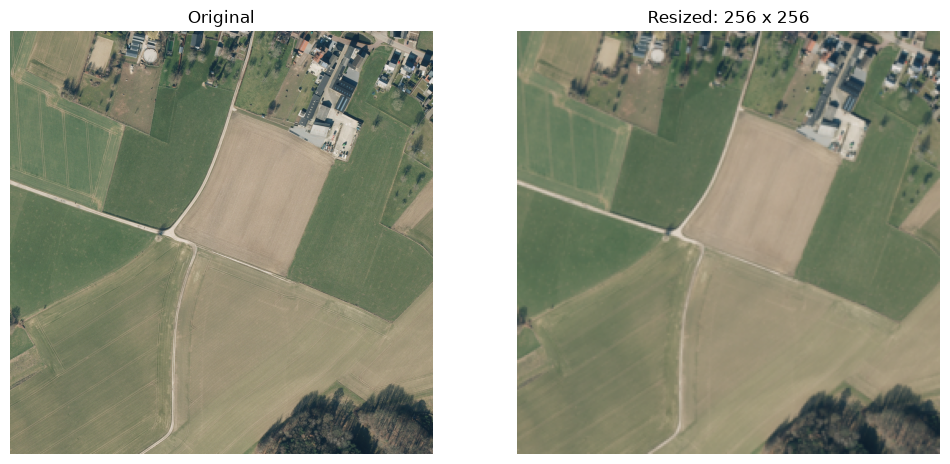

In [12]:
pair = pairs_df[pairs_df["split"] == "train"].iloc[0]

with Image.open(pair["image"]) as source:
    image = source.copy()

with Image.open(pair["mask"]) as source:
    mask = source.copy()

size = (256, 256)

resized_image = image.resize(size, Image.Resampling.BILINEAR)
resized_mask = mask.resize(size, Image.Resampling.NEAREST)

print("Original size:", image.size)
print("Resized image:", resized_image.size)
print("Resized mask:", resized_mask.size)

assert resized_image.size == resized_mask.size
assert np.isin(np.array(resized_mask), np.unique(np.array(mask))).all()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image)
axes[0].set_title("Original")
axes[1].imshow(resized_image)
axes[1].set_title("Resized: 256 x 256")

for axis in axes:
    axis.axis("off")

plt.show()

The image resize looks good, as we do not seem to lose a lot of information. Small details still require closer inspection, as I am not certain that we are loosing details.

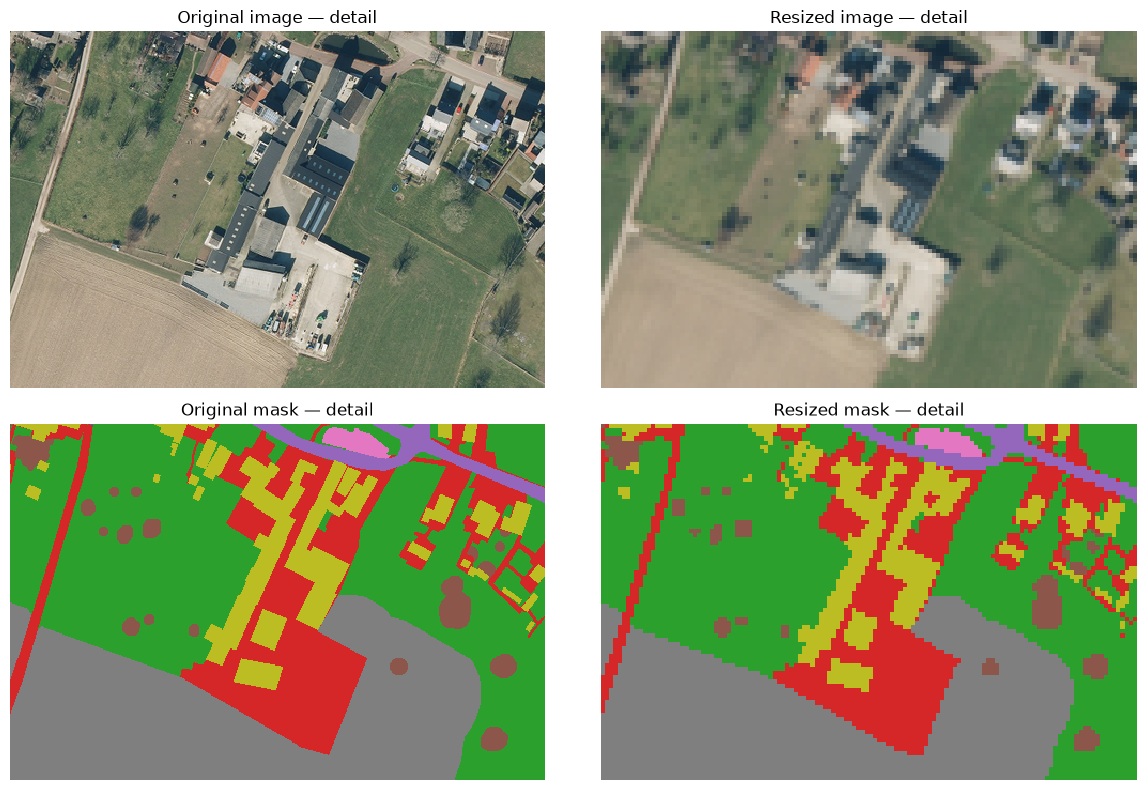

In [10]:
width, height = image.size
original_area = (width // 2, 0, width, height // 3)

width, height = resized_image.size
resized_area = (width // 2, 0, width, height // 3)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(image.crop(original_area), interpolation="nearest")
axes[0, 1].imshow(resized_image.crop(resized_area), interpolation="nearest")

axes[1, 0].imshow(
    mask.crop(original_area), cmap="tab10",
    vmin=0, vmax=9, interpolation="nearest"
)
axes[1, 1].imshow(
    resized_mask.crop(resized_area), cmap="tab10",
    vmin=0, vmax=9, interpolation="nearest"
)

axes[0, 0].set_title("Original image — detail")
axes[0, 1].set_title("Resized image — detail")
axes[1, 0].set_title("Original mask — detail")
axes[1, 1].set_title("Resized mask — detail")

for axis in axes.flat:
    axis.axis("off")

plt.tight_layout()
plt.show()

The masks seems to not lose major details, however the image became with a worst resolution. 

For the first baseline, I will resize images and masks to 256 x 256 pixels, as the first experiments with 512 x 512, did not go so well and it took a long time to run the project. Using bilinear interpolation for images and nearest-neighbour interpolation for masks. This simplifies batching but may remove details and distort non-square images.

## Preparing Mask Labels
Changing labels from 1-8 to 0-7 and assign them to the pixels.

In [13]:
original_labels = np.array(resized_mask, dtype=np.int64)

training_mask = original_labels - 1
training_mask[original_labels == 0] = 255

print("Original IDs:", np.unique(original_labels))
print("Training IDs:", np.unique(training_mask))

assert np.isin(training_mask, [0, 1, 2, 3, 4, 5, 6, 7, 255]).all()
assert np.array_equal(training_mask == 255, original_labels == 0)

Original IDs: [0 2 3 4 5 6 7 8]
Training IDs: [  1   2   3   4   5   6   7 255]


## Preparing Image Values and Dimensions (Scaling)
I will scale image values from 0-255 to 0-1 and move RGB channels to the first dimension

In [14]:
training_image = np.array(resized_image, dtype=np.float32) / 255
training_image=training_image.transpose(2, 0, 1)

print("Image shape:", training_image.shape)
print("Image type:", training_image.dtype)
print("Image range:", training_image.min(),"to", training_image.max())

print("Mask shape:", training_mask.shape)
print("Mask type:", training_mask.dtype)

assert training_image.shape[1:] == training_mask.shape
assert training_image.min() >= 0 and training_image.max() <= 1

Image shape: (3, 256, 256)
Image type: float32
Image range: 0.05490196 to 0.9098039
Mask shape: (256, 256)
Mask type: int64


After this scaling step, we have our image RGB channels ranging from 0.05 to 0.92. Now in the image shape, first come the three chanels and after it the size (heigth x width). The index of the "Unkown" pixels have become 255, instead of 0.

## Reusable Preprocessing Function

The preprocessing function and dataset class are now stored in `src/dataset.py`. Both this notebook and the baseline import the same implementation; the transformations are unchanged.


In [15]:
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.dataset import prepare_pair, LandCoverDataset

prepared_image, prepared_mask = prepare_pair(
    pair["image"], pair["mask"]
)

assert np.array_equal(prepared_image, training_image)
assert np.array_equal(prepared_mask, training_mask)

print("Preprocessing results match.")

Preprocessing results match.


## Converting Arrays to Pytorch Tensors
I will convert the prepared image and mask into PyTorch tensors

In [16]:
import torch

image_tensor = torch.from_numpy(prepared_image)
mask_tensor = torch.from_numpy(prepared_mask)

print("Image:", image_tensor.shape, image_tensor.dtype)
print("Mask:", mask_tensor.shape, mask_tensor.dtype)

Image: torch.Size([3, 256, 256]) torch.float32
Mask: torch.Size([256, 256]) torch.int64


## Loading Prepared Batches

I will load pairs when needed, group them into batches and check their shapes, types and values.

In [17]:
from torch.utils.data import DataLoader

loaders = {}

for split in ["train", "validation", "test"]:
    data = LandCoverDataset(pairs_df[pairs_df["split"] == split])

    loaders[split] = DataLoader(
        data, batch_size=2, shuffle=(split == "train"),
        num_workers=0, generator=torch.Generator().manual_seed(42)
    )

    images, masks = next(iter(loaders[split]))

    assert images.shape == (2, 3, 256, 256)
    assert masks.shape == (2, 256, 256)
    assert images.dtype == torch.float32
    assert masks.dtype == torch.int64
    assert images.min() >= 0 and images.max() <= 1
    assert (((masks >= 0) & (masks <= 7)) | (masks == 255)).all()

    print(split, "batch checked successfully.")

train batch checked successfully.
validation batch checked successfully.
test batch checked successfully.


## Conclusion

- Validated 2,687 image–mask pairs across 75 regions; no exact duplicate images or pairs were found.
- Created and saved separate geographical splits for training, validation and test.
- Confirmed all eight classes are present in every split, with different proportions.
- Prepared resizing to 512 × 512, image scaling to 0–1 and class ID conversion, marking Unknown as 255.
- Created a reusable preprocessing function and PyTorch DataLoaders; one batch from each split passed the checks.
- Class imbalance and detail loss from resizing remain limitations.
- Next: develop the baseline, ignore Unknown in the loss and metrics, and keep the test set fixed.